<a href="https://colab.research.google.com/github/MoeTahech/real-fake-face-detection-thesis/blob/main/notebooks/11_seeds_and_confidence_intervals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 11 — Phase 11: Statistical Rigor (Bootstrap Confidence Intervals + Multiple Seeds)

**Question this phase answers:** "Are the differences between our models *real*, or just luck?"

**Exam analogy:** one exam score doesn't prove a student is better than another. Two things make a comparison fair:
1. **Part A — Bootstrap (no retraining):** re-grade the *same* exam many times using random re-samples of the questions. If the score barely moves, the result is stable. This gives a **95% confidence interval (CI)**.
2. **Part B — Multiple seeds (retraining):** let the student take the course again 3 times with a different random start (different random initial weights, shuffling and flips). If the score is similar every time, it is not luck.

**What stays fixed vs. what changes**
- Fixed: the training data, the test data, the recipe (ResNet18, `layer4` unfrozen, Adam, lr 1e-4, batch 64, 5 epochs).
- Changed: only the random seed. So we measure *training noise*, nothing else.

**Run order:** Section 1 (setup + data) → Section 2 (Part A) → Section 3 (Part B, long, resumable) → Section 4 (summary + CIs on the new runs).
Everything is saved to Drive, so after a disconnect just re-run Section 1 and then the cell you were on.

### Step 1 — GPU and Google Drive

In [ ]:
!nvidia-smi

Wed Oct 14 10:31:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
CHECKPOINT_DIR = '/content/drive/MyDrive/thesis_checkpoints'
SEED_DIR  = f'{CHECKPOINT_DIR}/seed_runs'          # new checkpoints
PRED_DIR  = f'{SEED_DIR}/preds'                    # cached per-image predictions
for d in [CHECKPOINT_DIR, SEED_DIR, PRED_DIR]:
    os.makedirs(d, exist_ok=True)
print("Drive ready:", SEED_DIR)

Mounted at /content/drive
Drive ready: /content/drive/MyDrive/thesis_checkpoints/seed_runs


### Step 2 — Settings (edit only this cell)
- `SEEDS`: which seeds to train. 3 seeds is the minimum that gives a std.
- `P2_TRAIN_PER_CLASS`: `None` = full 100k images (same as Phase 2, honest comparison, slowest). A number such as `20000` trains P2 seeds on a subset (clearly label it as such in the thesis).
- Rough T4 time per run: P6 ≈ 25 min, P9 ≈ 25 min, P2 (full) ≈ 45-60 min. Total for 3 seeds ≈ 4-5 hours, over several sessions if needed.

In [ ]:
SEEDS = [0, 1, 2]
EPOCHS = 5
BATCH_SIZE = 64
LR = 1e-4
P2_TRAIN_PER_CLASS = None     # None = full 100k; or e.g. 20000
N_BOOT = 1000                 # bootstrap resamples

### Step 3 — Kaggle access (Colab Secrets: `KAGGLE_USERNAME`, `KAGGLE_KEY`)

In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = "YOUR_KAGGLE_API_TOKEN_HERE"

### Step 4 — Download the three datasets (needed every new session)

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d xhlulu/140k-real-and-fake-faces
!unzip -q 140k-real-and-fake-faces.zip -d data_raw
!kaggle datasets download -d manjilkarki/deepfake-and-real-images
!unzip -q deepfake-and-real-images.zip -d data_raw_2
!kaggle datasets download -d bwandowando/faces-dataset-using-stable-diffusion-v14
!unzip -q faces-dataset-using-stable-diffusion-v14.zip -d data_diffusion
print("All three datasets downloaded.")

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [00:41<00:00, 96.5MB/s]

Dataset URL: https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images
License(s): unknown
100% 1.68G/1.68G [00:23<00:00, 77.7MB/s]

Dataset URL: https://www.kaggle.com/datasets/bwandowando/faces-dataset-using-stable-diffusion-v14
License(s): CC0-1.0
100% 1.10G/1.10G [00:15<00:00, 76.5MB/s]

All three datasets downloaded.


### Step 5 — Locate folders (same helpers as every earlier notebook)

In [ ]:
import os, random, json
import numpy as np

def find_real_fake_folders(root):
    out = []
    for dp, dn, _ in os.walk(root):
        low = [d.lower() for d in dn]
        if "real" in low and "fake" in low: out.append(dp)
    return out

def find_split(root, kw):
    c = find_real_fake_folders(root); m = [x for x in c if kw in x.lower()]
    if not m: raise FileNotFoundError(f"No folder containing '{kw}' under {root}. Found: {c}")
    return m[0]

def find_class_dir(split_root, cls):
    for d in os.listdir(split_root):
        if d.lower() == cls: return os.path.join(split_root, d)
    raise FileNotFoundError(f"No '{cls}' folder in {split_root}")

def find_all_images(root, exts=(".jpg", ".jpeg", ".png")):
    out = []
    for dp, _, fn in os.walk(root):
        for f in fn:
            if f.lower().endswith(exts): out.append(os.path.join(dp, f))
    return out

styleGAN_train = find_split("data_raw", "train")
styleGAN_val   = find_split("data_raw", "val")     # matches 'valid' or 'val'
styleGAN_test  = find_split("data_raw", "test")
faceswap_train = find_split("data_raw_2", "train")
faceswap_test  = find_split("data_raw_2", "test")
diffusion_images = sorted(find_all_images("data_diffusion"))   # sorted -> reproducible split
print("StyleGAN train/val/test:", styleGAN_train, styleGAN_val, styleGAN_test)
print("Face-swap train/test:   ", faceswap_train, faceswap_test)
print("Diffusion images:", len(diffusion_images))

StyleGAN train/val/test: data_raw/real_vs_fake/real-vs-fake/train data_raw/real_vs_fake/real-vs-fake/valid data_raw/real_vs_fake/real-vs-fake/test
Face-swap train/test:    data_raw_2/Dataset/Train data_raw_2/Dataset/Test
Diffusion images: 2536


### Step 6 — Build the data (fixed for ALL seeds)

All splits below use **sorted file lists + a fixed seed**, so they are identical every session and identical across seeds. The diffusion 60/40 split is also saved to Drive so it never changes.

**Important note on the diffusion split.** In Phase 9 the file list was *not* sorted before shuffling, so the Phase 9 held-out set may not be exactly the same images as the one built here (file order on disk can differ between Colab sessions). For the **new** Phase 9 seeds this is irrelevant: they are trained and tested on this notebook's split, which is leak-free by construction. For the **original** Phase 9 checkpoint (`p9_orig`) it means some "held-out" images here might have been in its training set, so treat `p9_orig` on diffusion as *unverified* and base the P9 claims on the new seeds.

In [ ]:
SPLIT_FILE = f"{SEED_DIR}/diffusion_split.json"
if os.path.exists(SPLIT_FILE):
    sp = json.load(open(SPLIT_FILE))
    diffusion_train_images   = [os.path.join("data_diffusion", p) for p in sp["train"]]
    diffusion_heldout_images = [os.path.join("data_diffusion", p) for p in sp["heldout"]]
    print("Loaded saved diffusion split from Drive.")
else:
    rng = random.Random(2024)
    shuf = diffusion_images[:]; rng.shuffle(shuf)
    k = int(len(shuf) * 0.6)
    diffusion_train_images, diffusion_heldout_images = shuf[:k], shuf[k:]
    rel = lambda L: [os.path.relpath(p, "data_diffusion") for p in L]
    json.dump({"train": rel(diffusion_train_images), "heldout": rel(diffusion_heldout_images)}, open(SPLIT_FILE, "w"))
    print("Created and saved diffusion split to Drive.")
assert not (set(diffusion_train_images) & set(diffusion_heldout_images)), "LEAK: train/held-out overlap"
print("Diffusion train pool:", len(diffusion_train_images), "| held-out:", len(diffusion_heldout_images))

Loaded saved diffusion split from Drive.
Diffusion train pool: 1521 | held-out: 1015


In [ ]:
def link(src, dst):
    if not os.path.exists(dst): os.symlink(os.path.abspath(src), dst)

# ---- P2 data: StyleGAN only (full, or a fixed subset) ----
def build_p2_data():
    if P2_TRAIN_PER_CLASS is None:
        os.makedirs("data_p2", exist_ok=True)
        for name, src in [("train", styleGAN_train), ("val", styleGAN_val)]:
            dst = f"data_p2/{name}"
            if not os.path.exists(dst): os.symlink(os.path.abspath(src), dst)
    else:
        rng = random.Random(42)
        for name, src, n in [("train", styleGAN_train, P2_TRAIN_PER_CLASS), ("val", styleGAN_val, max(1000, P2_TRAIN_PER_CLASS // 5))]:
            for cls in ["real", "fake"]:
                d = f"data_p2/{name}/{cls}"; os.makedirs(d, exist_ok=True)
                cd = find_class_dir(src, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
                for f in files[:n]: link(os.path.join(cd, f), os.path.join(d, f))
build_p2_data()

# ---- P6 data: StyleGAN + face-swap (same builder logic as Phase 6) ----
def build_p6_data(dst_root, n_train=15000, n_val=2000, seed=42):
    rng = random.Random(seed)
    for cls in ["real", "fake"]:
        os.makedirs(f"{dst_root}/train/{cls}", exist_ok=True); os.makedirs(f"{dst_root}/val/{cls}", exist_ok=True)
        for src_root in [styleGAN_train, faceswap_train]:
            cd = find_class_dir(src_root, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
            chosen = files[:n_train + n_val]
            tag = os.path.basename(os.path.normpath(src_root))
            for f in chosen[:n_train]:  link(os.path.join(cd, f), f"{dst_root}/train/{cls}/{tag}_{f}")
            for f in chosen[n_train:]:  link(os.path.join(cd, f), f"{dst_root}/val/{cls}/{tag}_{f}")
build_p6_data("data_p6")

# ---- P9 data: P6 recipe + ~1,500 diffusion fakes (same logic as Phase 9) ----
def build_p9_data(dst_root, n_train=15000, n_val=2000, n_diff_train=1500, n_diff_val=200, seed=42):
    rng = random.Random(seed)
    for cls in ["real", "fake"]:
        os.makedirs(f"{dst_root}/train/{cls}", exist_ok=True); os.makedirs(f"{dst_root}/val/{cls}", exist_ok=True)
        for src_root in [styleGAN_train, faceswap_train]:
            cd = find_class_dir(src_root, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
            chosen = files[:n_train + n_val]
            tag = os.path.basename(os.path.normpath(src_root))
            for f in chosen[:n_train]:  link(os.path.join(cd, f), f"{dst_root}/train/{cls}/{tag}_{f}")
            for f in chosen[n_train:]:  link(os.path.join(cd, f), f"{dst_root}/val/{cls}/{tag}_{f}")
    pool = diffusion_train_images[:]; rng.shuffle(pool)
    chosen = pool[:n_diff_train + n_diff_val]
    for i, p in enumerate(chosen[:n_diff_train]): link(p, f"{dst_root}/train/fake/diffusion_{i}_{os.path.basename(p)}")
    for i, p in enumerate(chosen[n_diff_train:]):  link(p, f"{dst_root}/val/fake/diffusion_{i}_{os.path.basename(p)}")
build_p9_data("data_p9")

for d in ["data_p2", "data_p6", "data_p9"]:
    print(d, {s: {c: len(os.listdir(f"{d}/{s}/{c}")) for c in ["real", "fake"]} for s in ["train", "val"]})

data_p2 {'train': {'real': 50000, 'fake': 50000}, 'val': {'real': 10000, 'fake': 10000}}
data_p6 {'train': {'real': 30000, 'fake': 30000}, 'val': {'real': 4000, 'fake': 4000}}
data_p9 {'train': {'real': 30000, 'fake': 31500}, 'val': {'real': 4000, 'fake': 4021}}


### Step 7 — Build the three evaluation sets (same for every model)

In [ ]:
def build_eval_subset(source_root, dst_root, n_per_class, seed=99):
    rng = random.Random(seed)
    for cls in ["real", "fake"]:
        os.makedirs(f"{dst_root}/{cls}", exist_ok=True)
        cd = find_class_dir(source_root, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
        for f in files[:n_per_class]: link(os.path.join(cd, f), f"{dst_root}/{cls}/{f}")

build_eval_subset(styleGAN_test, "eval_stylegan", 5000)
build_eval_subset(faceswap_test, "eval_faceswap", 5000)

# Diffusion held-out fakes + equal number of real photos from the StyleGAN test split
def build_eval_diffusion(dst_root, fake_paths, real_dir, seed=7):
    rng = random.Random(seed)
    os.makedirs(f"{dst_root}/fake", exist_ok=True); os.makedirs(f"{dst_root}/real", exist_ok=True)
    reals = sorted(os.listdir(real_dir)); rng.shuffle(reals); reals = reals[:len(fake_paths)]
    for i, p in enumerate(sorted(fake_paths)): link(p, f"{dst_root}/fake/{i}_{os.path.basename(p)}")
    for i, f in enumerate(reals):              link(os.path.join(real_dir, f), f"{dst_root}/real/{i}_{f}")
build_eval_diffusion("eval_diffusion", diffusion_heldout_images, find_class_dir(styleGAN_test, "real"))

EVAL_SETS = {"stylegan": "eval_stylegan", "faceswap": "eval_faceswap", "diffusion": "eval_diffusion"}
for k, v in EVAL_SETS.items():
    print(k, {c: len(os.listdir(f"{v}/{c}")) for c in ["real", "fake"]})

stylegan {'real': 5000, 'fake': 5000}
faceswap {'real': 5000, 'fake': 5000}
diffusion {'real': 1015, 'fake': 1015}


### Step 8 — Evaluation helpers

`get_preds` evaluates a checkpoint on the three test sets **once** and caches every image's probability to Drive. After that, all statistics (bootstrap, tables) are computed from the cache with no GPU.

We use the same name-based class remap as before (`class_to_idx["real"]`), and AUC is computed on the probability of "real".

In [ ]:
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
std_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), normalize])

def load_resnet(path):
    ck = torch.load(path, map_location=device)
    m = models.resnet18(weights=None); m.fc = nn.Linear(m.fc.in_features, 2)
    m.load_state_dict(ck["model_state"]); m.to(device).eval()
    return m, ck["class_to_idx"]

@torch.no_grad()
def predict_dir(model, cidx, test_dir, tf):
    real_idx = cidx["real"]
    ds = datasets.ImageFolder(test_dir, transform=tf)
    loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=2)
    remap = {i: cidx[n.lower()] for n, i in ds.class_to_idx.items()}
    is_real, p_real = [], []
    for x, y in loader:
        p = torch.softmax(model(x.to(device)), 1)[:, real_idx].cpu().numpy()
        p_real.extend(p); is_real.extend([remap[int(t)] == real_idx for t in y])
    return np.array(is_real, dtype=bool), np.array(p_real, dtype=np.float64)

def get_preds(tag, ckpt_path, tf=std_transform):
    f = f"{PRED_DIR}/{tag}.npz"
    if os.path.exists(f):
        z = np.load(f); return {d: (z[f"{d}__real"], z[f"{d}__p"]) for d in EVAL_SETS}
    model, cidx = load_resnet(ckpt_path)
    out, save = {}, {}
    for d, path in EVAL_SETS.items():
        r, p = predict_dir(model, cidx, path, tf); out[d] = (r, p)
        save[f"{d}__real"] = r; save[f"{d}__p"] = p
    np.savez(f, **save); del model; torch.cuda.empty_cache()
    return out

from sklearn.metrics import roc_auc_score
def quick(tag, preds):
    return "  ".join(f"{d}: acc={((p >= .5) == r).mean():.4f} auc={roc_auc_score(r, p):.4f}" for d, (r, p) in preds.items())

## Section 2 — Part A: Bootstrap confidence intervals (no retraining)

**What happens:** we load the *original* checkpoints (P2, P6, P9, and P8 if present), score every test image once, then re-sample the test set 1,000 times (with replacement, real and fake images separately). Each resample gives one AUC; the middle 95% of those is the CI.

**Paired comparison:** for "is model A really better than B?" we use the **same** resamples for both models and look at the *difference* in AUC. If the 95% CI of the difference does **not** contain 0, the gap is not explained by test-set luck.

In [ ]:
ORIG = {"p2_orig": f"{CHECKPOINT_DIR}/best_model_finetuned.pth",
        "p6_orig": f"{CHECKPOINT_DIR}/best_model_mixed.pth",
        "p9_orig": f"{CHECKPOINT_DIR}/best_model_threesource.pth"}
PREDS = {}
for tag, path in ORIG.items():
    PREDS[tag] = get_preds(tag, path)
    print(f"{tag:8s}", quick(tag, PREDS[tag]))

print()
print("Sanity check vs. your earlier reports (small differences are expected: different eval subsets)")
print("  P2: StyleGAN ~98.7%/.999 | face-swap AUC ~.52 | diffusion AUC ~.28")
print("  P6: StyleGAN ~95.5%/.995 | face-swap ~82%/.928 | diffusion AUC ~.55")
print("  P9: StyleGAN AUC ~.994   | face-swap AUC ~.913 | diffusion ~98.6%/.999 (see caveat in Step 6)")

p2_orig  stylegan: acc=0.9876 auc=0.9992  faceswap: acc=0.4979 auc=0.5253  diffusion: acc=0.4961 auc=0.2822
p6_orig  stylegan: acc=0.9574 auc=0.9954  faceswap: acc=0.8232 auc=0.9272  diffusion: acc=0.5325 auc=0.5626
p9_orig  stylegan: acc=0.9586 auc=0.9940  faceswap: acc=0.8205 auc=0.9130  diffusion: acc=0.9833 auc=0.9996

Sanity check vs. your earlier reports (small differences are expected: different eval subsets)
  P2: StyleGAN ~98.7%/.999 | face-swap AUC ~.52 | diffusion AUC ~.28
  P6: StyleGAN ~95.5%/.995 | face-swap ~82%/.928 | diffusion AUC ~.55
  P9: StyleGAN AUC ~.994   | face-swap AUC ~.913 | diffusion ~98.6%/.999 (see caveat in Step 6)


In [ ]:
# OPTIONAL: Phase 8 (frequency-domain model). Skipped automatically if the checkpoint is missing or differs.
class ToFreq:
    def __call__(self, img):
        ch = [torch.log(torch.abs(torch.fft.fftshift(torch.fft.fft2(img[c]))) + 1e-8) for c in range(img.shape[0])]
        f = torch.stack(ch); return (f - f.mean()) / (f.std() + 1e-8)
freq_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), ToFreq()])
try:
    PREDS["p8_orig"] = get_preds("p8_orig", f"{CHECKPOINT_DIR}/best_model_frequency.pth", tf=freq_transform)
    print("p8_orig", quick("p8_orig", PREDS["p8_orig"]))
except Exception as e:
    print("P8 skipped:", repr(e)[:200], "\n(Upload 08_frequency_domain.ipynb if you want this fixed.)")

p8_orig stylegan: acc=0.8346 auc=0.9168  faceswap: acc=0.5003 auc=0.5588  diffusion: acc=0.4473 auc=0.3025


In [ ]:
from scipy.stats import rankdata

def auc_fast(pos, neg):
    n1, n0 = len(pos), len(neg)
    r = rankdata(np.concatenate([pos, neg]))
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def paired_bootstrap(preds, tags, domain, n_boot=N_BOOT, seed=0):
    # Same resampled images for every model -> differences are *paired*.
    rng = np.random.default_rng(seed)
    r0 = preds[tags[0]][domain][0]
    for t in tags:
        assert np.array_equal(preds[t][domain][0], r0), f"Label order differs for {t}. Delete {PRED_DIR} and re-run."
    ip, ineg = np.where(r0)[0], np.where(~r0)[0]
    auc = {t: np.empty(n_boot) for t in tags}; acc = {t: np.empty(n_boot) for t in tags}
    for b in range(n_boot):
        bp, bn = rng.choice(ip, len(ip)), rng.choice(ineg, len(ineg))
        for t in tags:
            p = preds[t][domain][1]
            auc[t][b] = auc_fast(p[bp], p[bn])
            acc[t][b] = ((p[bp] >= .5).sum() + (p[bn] < .5).sum()) / (len(bp) + len(bn))
    return auc, acc

def ci(x): return np.percentile(x, [2.5, 97.5])

def bootstrap_report(preds, tags, comparisons):
    tags = [t for t in tags if t in preds]
    rows, boots = [], {}
    for d in EVAL_SETS:
        auc, acc = paired_bootstrap(preds, tags, d); boots[d] = auc
        for t in tags:
            r, p = preds[t][d]
            lo, hi = ci(auc[t]); alo, ahi = ci(acc[t])
            rows.append((t, d, ((p >= .5) == r).mean(), alo, ahi, roc_auc_score(r, p), lo, hi))
    import pandas as pd
    df = pd.DataFrame(rows, columns=["model", "domain", "acc", "acc_lo", "acc_hi", "auc", "auc_lo", "auc_hi"])
    print("=== 95% bootstrap CIs ===")
    print(df.round(4).to_string(index=False))
    print("\n=== Paired AUC differences (A minus B) ===")
    out = []
    for a, b, d in comparisons:
        if a not in preds or b not in preds: continue
        auc = boots[d]; diff = auc[a] - auc[b]; lo, hi = ci(diff)
        verdict = "SIGNIFICANT (CI excludes 0)" if (lo > 0 or hi < 0) else "NOT distinguishable from 0"
        print(f"{a:10s} - {b:10s} [{d:9s}]  diff={diff.mean():+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")
        out.append((a, b, d, diff.mean(), lo, hi, verdict))
    return df, out

COMPARISONS_ORIG = [
    ("p6_orig", "p2_orig", "faceswap"),    # does mixed training fix face-swap?
    ("p6_orig", "p2_orig", "stylegan"),    # what does it cost on StyleGAN?
    ("p9_orig", "p6_orig", "diffusion"),   # does adding diffusion fix diffusion?
    ("p9_orig", "p2_orig", "diffusion"),
    ("p9_orig", "p6_orig", "faceswap"),    # cost of adding diffusion on face-swap
    ("p8_orig", "p2_orig", "faceswap"),    # the small +0.035 frequency gain
    ("p8_orig", "p2_orig", "diffusion"),
    ("p6_orig", "p2_orig", "diffusion"),
]
dfA, diffsA = bootstrap_report(PREDS, list(ORIG) + ["p8_orig"], COMPARISONS_ORIG)
dfA.to_csv(f"{SEED_DIR}/partA_bootstrap_cis.csv", index=False)
print("\nSaved to", f"{SEED_DIR}/partA_bootstrap_cis.csv")

=== 95% bootstrap CIs ===
  model    domain    acc  acc_lo  acc_hi    auc  auc_lo  auc_hi
p2_orig  stylegan 0.9876  0.9854  0.9898 0.9992  0.9989  0.9994
p6_orig  stylegan 0.9574  0.9535  0.9613 0.9954  0.9945  0.9961
p9_orig  stylegan 0.9586  0.9547  0.9627 0.9940  0.9930  0.9950
p8_orig  stylegan 0.8346  0.8275  0.8419 0.9168  0.9117  0.9219
p2_orig  faceswap 0.4979  0.4952  0.5007 0.5253  0.5135  0.5361
p6_orig  faceswap 0.8232  0.8161  0.8310 0.9272  0.9223  0.9320
p9_orig  faceswap 0.8205  0.8132  0.8278 0.9130  0.9078  0.9183
p8_orig  faceswap 0.5003  0.4956  0.5053 0.5588  0.5477  0.5708
p2_orig diffusion 0.4961  0.4921  0.4990 0.2822  0.2609  0.3029
p6_orig diffusion 0.5325  0.5192  0.5458 0.5626  0.5370  0.5873
p9_orig diffusion 0.9833  0.9778  0.9887 0.9996  0.9993  0.9998
p8_orig diffusion 0.4473  0.4340  0.4621 0.3025  0.2799  0.3254

=== Paired AUC differences (A minus B) ===
p6_orig    - p2_orig    [faceswap ]  diff=+0.4022  95% CI [+0.3909, +0.4136]  -> SIGNIFICANT (CI e

**How to read it:** a model has *below-chance* AUC if its whole CI is under 0.5 (e.g. P2 on diffusion). A gain such as P8's +0.035 is only a real gain if the paired CI of the difference excludes 0.

## Section 3 — Part B: Retrain with different seeds

**Why this is safe to interrupt:** each run writes a `.done` marker when finished. Re-running the cell skips finished runs and retrains unfinished ones. Runs go seed by seed (P6, P9, then the long P2), so you get usable results early.

**What the seed controls:** the random start of the new final layer, the order images are shown, and the random flips. It does *not* change which images are in train/val/test.

In [ ]:
%%writefile train_seeded.py
import argparse, os, json, random
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from tqdm import tqdm

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def get_dataloaders(data_dir, batch_size, seed, img_size=224):
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    train_tf = transforms.Compose([transforms.Resize((img_size, img_size)), transforms.RandomHorizontalFlip(), transforms.ToTensor(), normalize])
    val_tf = transforms.Compose([transforms.Resize((img_size, img_size)), transforms.ToTensor(), normalize])
    train_set = datasets.ImageFolder(f"{data_dir}/train", transform=train_tf)
    val_set = datasets.ImageFolder(f"{data_dir}/val", transform=val_tf)
    g = torch.Generator(); g.manual_seed(seed)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2, generator=g)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=2)
    return train_loader, val_loader, train_set.class_to_idx

def build_model():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    for p in m.parameters(): p.requires_grad = False
    for p in m.layer4.parameters(): p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, 2)      # seeded random init
    return m

def run_epoch(model, loader, criterion, optimizer, device, train, quiet):
    model.train() if train else model.eval()
    tl, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in tqdm(loader, disable=quiet, desc="train" if train else "val"):
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            if train: loss.backward(); optimizer.step()
            tl += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return tl / total, correct / total

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", required=True); ap.add_argument("--save_path", required=True)
    ap.add_argument("--seed", type=int, required=True); ap.add_argument("--epochs", type=int, default=5)
    ap.add_argument("--batch_size", type=int, default=64); ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--quiet", action="store_true")
    a = ap.parse_args()
    set_seed(a.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    train_loader, val_loader, cidx = get_dataloaders(a.data_dir, a.batch_size, a.seed)
    print("Class mapping:", cidx, "| seed:", a.seed)
    model = build_model().to(device); criterion = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    print(f"Trainable parameters: {sum(p.numel() for p in params):,}")
    opt = torch.optim.Adam(params, lr=a.lr)
    best, log = 0.0, []
    for ep in range(a.epochs):
        tl, ta = run_epoch(model, train_loader, criterion, opt, device, True, a.quiet)
        vl, va = run_epoch(model, val_loader, criterion, opt, device, False, a.quiet)
        print(f"epoch {ep+1}/{a.epochs} train_loss={tl:.4f} train_acc={ta:.4f} val_loss={vl:.4f} val_acc={va:.4f}")
        log.append({"epoch": ep + 1, "train_loss": tl, "train_acc": ta, "val_loss": vl, "val_acc": va})
        if va > best:
            best = va; torch.save({"model_state": model.state_dict(), "class_to_idx": cidx}, a.save_path)
            print(f"  saved best (val_acc={va:.4f})")
    json.dump({"best_val_acc": best, "seed": a.seed, "log": log}, open(a.save_path + ".done", "w"))
    print("Done. Best val acc:", best)

if __name__ == "__main__":
    main()

Writing train_seeded.py


In [ ]:
RUNS = {"p6": "data_p6", "p9": "data_p9", "p2": "data_p2"}   # order: short runs first, long P2 last
def run_name(m, s): return f"{m}_seed{s}"
def ckpt_path(m, s): return f"{SEED_DIR}/{run_name(m, s)}.pth"

for seed in SEEDS:
    for m, data_dir in RUNS.items():
        path = ckpt_path(m, seed)
        if os.path.exists(path + ".done"):
            print(f"[skip] {run_name(m, seed)} already finished"); continue
        print(f"\n===== TRAINING {run_name(m, seed)} =====")
        get_ipython().system(f'python train_seeded.py --data_dir {data_dir} --save_path "{path}" --seed {seed} --epochs {EPOCHS} --batch_size {BATCH_SIZE} --lr {LR} --quiet')
print("\nAll requested runs are finished (or skipped).")

[skip] p6_seed0 already finished
[skip] p9_seed0 already finished
[skip] p2_seed0 already finished
[skip] p6_seed1 already finished
[skip] p9_seed1 already finished
[skip] p2_seed1 already finished
[skip] p6_seed2 already finished
[skip] p9_seed2 already finished

===== TRAINING p2_seed2 =====
Class mapping: {'fake': 0, 'real': 1} | seed: 2
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 182MB/s]
Trainable parameters: 8,394,754
epoch 1/5 train_loss=0.1456 train_acc=0.9411 val_loss=0.0857 val_acc=0.9671
  saved best (val_acc=0.9671)
epoch 2/5 train_loss=0.0516 train_acc=0.9810 val_loss=0.0622 val_acc=0.9766
  saved best (val_acc=0.9766)
epoch 3/5 train_loss=0.0336 train_acc=0.9882 val_loss=0.0462 val_acc=0.9826
  saved best (val_acc=0.9826)
epoch 4/5 train_loss=0.0245 train_acc=0.9912 val_loss=0.0430 val_acc=0.9850
  saved best (val_acc=0.9850)
epoch 5/5 train_loss=0.0185 

## Section 4 — Summary: mean ± std across seeds, plus CIs on the new runs

In [ ]:
import pandas as pd
finished = {(m, s) for m in RUNS for s in SEEDS if os.path.exists(ckpt_path(m, s) + ".done")}
print("Finished runs:", sorted(finished))
for (m, s) in sorted(finished):
    PREDS[run_name(m, s)] = get_preds(run_name(m, s), ckpt_path(m, s))
    print(f"{run_name(m, s):10s}", quick(run_name(m, s), PREDS[run_name(m, s)]))

Finished runs: [('p2', 0), ('p2', 1), ('p2', 2), ('p6', 0), ('p6', 1), ('p6', 2), ('p9', 0), ('p9', 1), ('p9', 2)]
p2_seed0   stylegan: acc=0.9883 auc=0.9993  faceswap: acc=0.4934 auc=0.5154  diffusion: acc=0.4970 auc=0.2836
p2_seed1   stylegan: acc=0.9845 auc=0.9988  faceswap: acc=0.4886 auc=0.4877  diffusion: acc=0.4941 auc=0.3123
p2_seed2   stylegan: acc=0.9844 auc=0.9991  faceswap: acc=0.4952 auc=0.5039  diffusion: acc=0.4956 auc=0.3178
p6_seed0   stylegan: acc=0.9720 auc=0.9962  faceswap: acc=0.7876 auc=0.9091  diffusion: acc=0.5143 auc=0.5687
p6_seed1   stylegan: acc=0.9660 auc=0.9955  faceswap: acc=0.7985 auc=0.8867  diffusion: acc=0.5507 auc=0.6774
p6_seed2   stylegan: acc=0.9702 auc=0.9957  faceswap: acc=0.7863 auc=0.8979  diffusion: acc=0.5611 auc=0.6408
p9_seed0   stylegan: acc=0.9637 auc=0.9953  faceswap: acc=0.8253 auc=0.9170  diffusion: acc=0.9778 auc=0.9984
p9_seed1   stylegan: acc=0.9674 auc=0.9961  faceswap: acc=0.8308 auc=0.9202  diffusion: acc=0.9867 auc=0.9989
p9_se

In [ ]:
NAMES = {"p2": "P2 single-source (StyleGAN)", "p6": "P6 two-source", "p9": "P9 three-source"}
rows = []
for m in RUNS:
    tags = [run_name(m, s) for s in SEEDS if (m, s) in finished]
    if not tags: continue
    for d in EVAL_SETS:
        accs = np.array([((PREDS[t][d][1] >= .5) == PREDS[t][d][0]).mean() for t in tags])
        aucs = np.array([roc_auc_score(PREDS[t][d][0], PREDS[t][d][1]) for t in tags])
        sd = lambda x: x.std(ddof=1) if len(x) > 1 else float("nan")
        orig = f"{m}_orig"
        o_auc = roc_auc_score(*PREDS[orig][d]) if orig in PREDS else float("nan")
        rows.append({"model": NAMES[m], "domain": d, "n_seeds": len(tags),
                     "acc_mean": accs.mean(), "acc_std": sd(accs),
                     "auc_mean": aucs.mean(), "auc_std": sd(aucs), "auc_min": aucs.min(), "auc_max": aucs.max(),
                     "auc_original_run": o_auc})
summary = pd.DataFrame(rows)
print(summary.round(4).to_string(index=False))
summary.to_csv(f"{SEED_DIR}/partB_seed_summary.csv", index=False)

print("\n--- Thesis-ready format (AUC, mean ± std over seeds) ---")
for d in EVAL_SETS:
    line = " | ".join(f"{NAMES[m].split()[0]}: {r.auc_mean:.3f} ± {r.auc_std:.3f}" for m in RUNS for r in summary[(summary.model == NAMES[m]) & (summary.domain == d)].itertuples())
    print(f"{d:10s} {line}")

                      model    domain  n_seeds  acc_mean  acc_std  auc_mean  auc_std  auc_min  auc_max  auc_original_run
              P6 two-source  stylegan        3    0.9694   0.0031    0.9958   0.0003   0.9955   0.9962            0.9954
              P6 two-source  faceswap        3    0.7908   0.0067    0.8979   0.0112   0.8867   0.9091            0.9272
              P6 two-source diffusion        3    0.5420   0.0246    0.6290   0.0553   0.5687   0.6774            0.5626
            P9 three-source  stylegan        3    0.9674   0.0037    0.9959   0.0005   0.9953   0.9963            0.9940
            P9 three-source  faceswap        3    0.8209   0.0127    0.9207   0.0040   0.9170   0.9249            0.9130
            P9 three-source diffusion        3    0.9818   0.0045    0.9987   0.0002   0.9984   0.9989            0.9996
P2 single-source (StyleGAN)  stylegan        3    0.9857   0.0022    0.9991   0.0003   0.9988   0.9993            0.9992
P2 single-source (StyleGAN)  fac

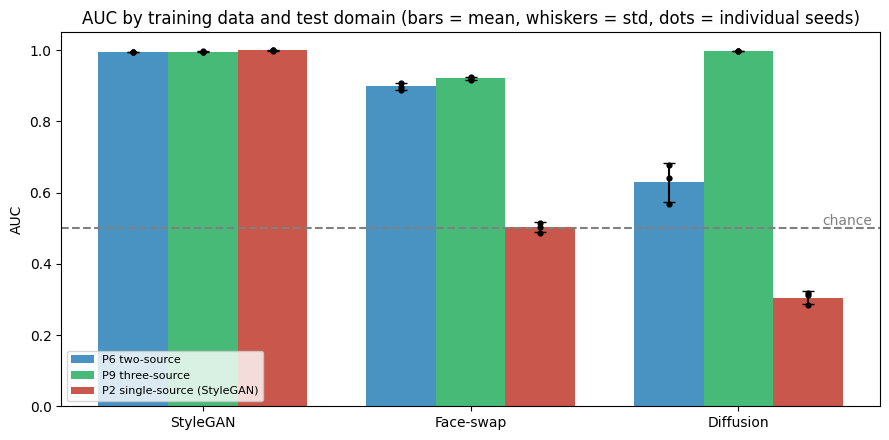

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4.5))
doms = list(EVAL_SETS); w = 0.26; colors = {"p2": "#c0392b", "p6": "#2980b9", "p9": "#27ae60"}
for j, m in enumerate(RUNS):
    sub = summary[summary.model == NAMES[m]].set_index("domain").reindex(doms)
    if sub.auc_mean.isna().all(): continue
    xs = np.arange(len(doms)) + (j - 1) * w
    ax.bar(xs, sub.auc_mean, w, yerr=sub.auc_std.fillna(0), capsize=4, color=colors[m], label=NAMES[m], alpha=.85)
    for i, d in enumerate(doms):
        for s in SEEDS:
            t = run_name(m, s)
            if t in PREDS: ax.scatter(xs[i], roc_auc_score(*PREDS[t][d]), color="k", s=12, zorder=3)
ax.axhline(0.5, ls="--", c="gray"); ax.text(len(doms) - .5, 0.51, "chance", color="gray", ha="right")
ax.set_xticks(range(len(doms))); ax.set_xticklabels(["StyleGAN", "Face-swap", "Diffusion"]); ax.set_ylabel("AUC"); ax.set_ylim(0, 1.05)
ax.set_title("AUC by training data and test domain (bars = mean, whiskers = std, dots = individual seeds)"); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.savefig(f"{SEED_DIR}/seeds_auc_barplot.png", dpi=200); plt.show()

In [ ]:
# Paired bootstrap on the NEW runs: does the effect hold in EVERY seed?
seed_tags = [run_name(m, s) for (m, s) in sorted(finished)]
all_diffs = []
for s in SEEDS:
    comps = [(f"p6_seed{s}", f"p2_seed{s}", "faceswap"), (f"p6_seed{s}", f"p2_seed{s}", "stylegan"),
             (f"p9_seed{s}", f"p6_seed{s}", "diffusion"), (f"p9_seed{s}", f"p2_seed{s}", "diffusion"),
             (f"p9_seed{s}", f"p6_seed{s}", "faceswap")]
    if not all(t in PREDS for c in comps[:1] for t in c[:2]): continue
    print(f"\n########## SEED {s} ##########")
    _, d = bootstrap_report(PREDS, [t for t in seed_tags if t.endswith(f"seed{s}")], comps)
    all_diffs += [(s,) + x for x in d]
pd.DataFrame(all_diffs, columns=["seed", "A", "B", "domain", "auc_diff", "ci_lo", "ci_hi", "verdict"]).to_csv(f"{SEED_DIR}/partB_paired_bootstrap_per_seed.csv", index=False)
print("\nSaved all tables/figures to", SEED_DIR)


########## SEED 0 ##########
=== 95% bootstrap CIs ===
   model    domain    acc  acc_lo  acc_hi    auc  auc_lo  auc_hi
p2_seed0  stylegan 0.9883  0.9861  0.9904 0.9993  0.9990  0.9995
p6_seed0  stylegan 0.9720  0.9685  0.9752 0.9962  0.9954  0.9969
p9_seed0  stylegan 0.9637  0.9599  0.9677 0.9953  0.9945  0.9961
p2_seed0  faceswap 0.4934  0.4898  0.4968 0.5154  0.5043  0.5265
p6_seed0  faceswap 0.7876  0.7799  0.7954 0.9091  0.9036  0.9149
p9_seed0  faceswap 0.8253  0.8179  0.8325 0.9170  0.9121  0.9219
p2_seed0 diffusion 0.4970  0.4936  0.5005 0.2836  0.2614  0.3048
p6_seed0 diffusion 0.5143  0.5054  0.5232 0.5687  0.5428  0.5934
p9_seed0 diffusion 0.9778  0.9714  0.9837 0.9984  0.9976  0.9992

=== Paired AUC differences (A minus B) ===
p6_seed0   - p2_seed0   [faceswap ]  diff=+0.3940  95% CI [+0.3828, +0.4047]  -> SIGNIFICANT (CI excludes 0)
p6_seed0   - p2_seed0   [stylegan ]  diff=-0.0031  95% CI [-0.0039, -0.0024]  -> SIGNIFICANT (CI excludes 0)
p9_seed0   - p6_seed0   [diffusi

### What to save for your report
- Part A: the CI table and the "Paired AUC differences" list.
- Part B: the mean ± std table and the bar plot (`seeds_auc_barplot.png`).
- The per-seed paired bootstrap: ideally every seed says SIGNIFICANT for P6 vs P2 on face-swap and P9 vs P6 on diffusion.

**Honest-writing tips**
- With 3 seeds, a std is a rough estimate. Also quote min–max, and say "n = 3".
- If P2 is trained on a subset, say so in the methodology.
- Bootstrap CIs capture *test-set* uncertainty; seeds capture *training* uncertainty. Report both.